# 27a. Reproducción de las pruebas de hipótesis

Este cuaderno regenera, desde las tablas congeladas de `entregable3/resultados/`, las tablas y figuras del
capítulo 27. Además **recalcula la corrección de Holm** a partir de los p-valores sin ajustar de cada prueba, para
comprobar que la decisión publicada sale del procedimiento preregistrado. Los p-valores sin ajustar los calculan
`entregable3/analisis/estad.py` (t pareada, Wilcoxon exacta, bootstrap jerárquico con 10 000 réplicas) y
`confirmatorio.py`; ejecutarlos de nuevo tarda unos 3 minutos y produce los mismos archivos byte a byte.

In [1]:
# Configuración común. El cuaderno funciona desde docs/ (Jupyter Book) o desde la raíz del repositorio.
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable3").is_dir())
RES = REPO / "entregable3" / "resultados"   # tablas congeladas del análisis (hash SHA-256 en el capítulo 21)
RUNS = REPO / "entregable3" / "results"     # corridas versionadas, sin pesos
CLASES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
COLOR = {"NAGFuse": "#c0392b", "ViT-B16": "#2e86c1", "RWCNet": "#27ae60", "GFN": "#8e44ad", "Celik-HC": "#d68910"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 4)
print("Repositorio:", REPO.name)

Repositorio: deep-learning-colaborativo


In [2]:
# Holm–Bonferroni: p ajustado del i-ésimo menor p = max_{j<=i} min(1, (m − j + 1) p_(j))
def holm(p: np.ndarray) -> np.ndarray:
    p = np.asarray(p, float); m = len(p); o = np.argsort(p)
    ajust = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o]))
    out = np.empty(m); out[o] = ajust
    return out

H1 = pd.read_csv(RES / "contrastes_H1_f1.csv")        # familia de m = 12 rivales, F1 macro limpio
H2 = pd.read_csv(RES / "contrastes_H2_ruido005.csv")  # familia de m = 10 rivales, F1 con ruido σ = 0.05
for nombre, t in [("H1", H1), ("H2", H2)]:
    p_max = np.max([holm(t[c]) for c in ["p_t", "p_w", "p_boot"]], axis=0)   # decisión: máximo de las tres pruebas
    print(f"{nombre}: m = {len(t)}, máxima discrepancia con la tabla publicada = {np.abs(p_max - t.p_max_holm).max():.2e}")
    assert np.allclose(p_max, t.p_max_holm), "La corrección de Holm no coincide"

H1: m = 12, máxima discrepancia con la tabla publicada = 2.17e-19
H2: m = 10, máxima discrepancia con la tabla publicada = 0.00e+00


In [3]:
# Tabla 27a.1: H1, F1 macro limpio. "Supera" exige p de Holm < 0.05, diferencia > δ = 0.02 y límite inferior del IC > 0
DELTA = 0.02
def tabla_contraste(t):
    return pd.DataFrame({"rival": t.rival, "semillas": t.R, "diferencia": t.media_dif,
                         "IC 95 %": [f"[{a:+.4f}, {b:+.4f}]" for a, b in zip(t.ic_lo, t.ic_hi)],
                         "p t (Holm)": t.p_t_holm, "p Wilcoxon (Holm)": t.p_w_holm, "p bootstrap (Holm)": t.p_boot_holm,
                         "p máx.": t.p_max_holm, "Cliff δ": t.cliff, "d_z": t.dz,
                         "supera": (t.p_max_holm < 0.05) & (t.media_dif > DELTA) & (t.ic_lo > 0)}) \
             .sort_values("diferencia").reset_index(drop=True)

T1 = tabla_contraste(H1)
assert (T1.supera.values == H1.sort_values("media_dif").supera.values).all()   # mismo veredicto que la tabla congelada
T1

,rival,semillas,diferencia,IC 95 %,p t (Holm),p Wilcoxon (Holm),p bootstrap (Holm),p máx.,Cliff δ,d_z,supera
0,RWCNet,20,-0.0004,"[-0.0096, +0.0088]",1.0000e+00,1.0000e+00,1.0000,1.0000,-0.1,-0.0276,False
1,ViT-B16,20,0.0002,"[-0.0110, +0.0118]",1.0000e+00,1.0000e+00,1.0000,1.0000,0.1,0.0089,False
2,GFN,20,0.0125,"[+0.0030, +0.0224]",5.6495e-03,5.0697e-03,0.0426,0.0426,0.5,0.8063,False
3,Celik-HC,20,0.0272,"[+0.0168, +0.0392]",9.2832e-06,3.8147e-05,0.0012,0.0012,0.9,1.4870,True
4,ResMsCapsule,20,0.0308,"[+0.0197, +0.0427]",5.6761e-06,8.5831e-05,0.0012,0.0012,0.8,1.5664,True
5,MbXception,12,0.0692,"[+0.0566, +0.0832]",3.1279e-09,3.9062e-03,0.0012,0.0039,1.0,6.0687,True
6,ResNet-18,12,0.0713,"[+0.0572, +0.0870]",8.6414e-08,3.9062e-03,0.0012,0.0039,1.0,4.2348,True
7,CNN,12,0.1110,"[+0.0956, +0.1283]",5.1220e-09,3.9062e-03,0.0012,0.0039,1.0,5.7398,True
8,FocusRCNet,12,0.1260,"[+0.1088, +0.1462]",1.6592e-08,3.9062e-03,0.0012,0.0039,1.0,5.0224,True
9,MobileNetV2,12,0.1291,"[+0.1123, +0.1477]",5.1220e-09,3.9062e-03,0.0012,0.0039,1.0,5.7325,True


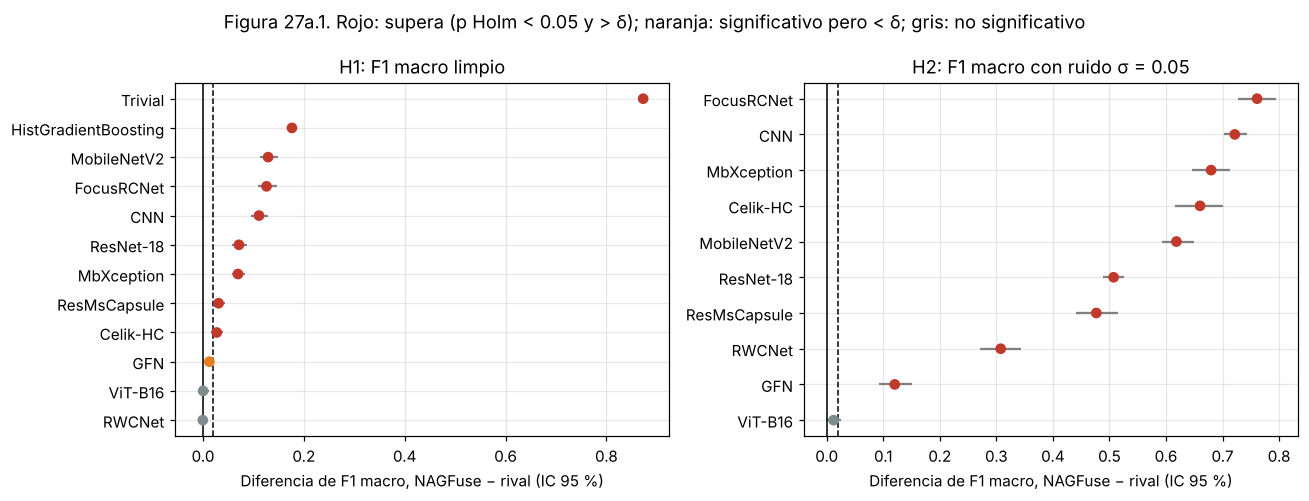

In [4]:
# Figura 27a.1: diferencias NAGFuse − rival con IC 95 % (H1 y H2)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, t, tit in [(ejes[0], H1, "H1: F1 macro limpio"), (ejes[1], H2, "H2: F1 macro con ruido σ = 0.05")]:
    t = t.sort_values("media_dif")
    col = np.where(t.supera, "#c0392b", np.where(t.p_max_holm < 0.05, "#e67e22", "#7f8c8d"))
    ax.errorbar(t.media_dif, t.rival, xerr=[t.media_dif - t.ic_lo, t.ic_hi - t.media_dif], fmt="none", ecolor="gray")
    ax.scatter(t.media_dif, t.rival, c=col, zorder=3)
    ax.axvline(0, color="black", lw=1); ax.axvline(DELTA, color="black", ls="--", lw=1)
    ax.set_title(tit); ax.set_xlabel("Diferencia de F1 macro, NAGFuse − rival (IC 95 %)")
fig.suptitle("Figura 27a.1. Rojo: supera (p Holm < 0.05 y > δ); naranja: significativo pero < δ; gris: no significativo")
plt.tight_layout()

**Interpretación.** En datos limpios NAGFuse supera por más de δ a 9 de los 12 rivales. Frente a GFN la diferencia
(+0.013) es menor que δ, y frente a RWCNet y ViT-B16 es prácticamente cero, con un intervalo que cruza el 0: H1 no se
cumple. Con ruido σ = 0.05 la
ventaja frente a las redes convolucionales es enorme, porque estas colapsan; frente a ViT-B16 la diferencia es
pequeña y no significativa, porque con ruido fuerte la compuerta deja decidir precisamente a la rama ViT.

In [5]:
# Tabla 27a.2: sensibilidad del veredicto de H1 a la métrica (MCC) y al subconjunto de semillas (0–9)
MCC = pd.read_csv(RES / "contrastes_H1_mcc.csv").set_index("rival")
S09 = pd.read_csv(RES / "contrastes_H1_seeds0-9.csv").set_index("rival")
sens = pd.DataFrame({"F1, todas las semillas": H1.set_index("rival").supera, "MCC, todas las semillas": MCC.supera,
                     "F1, semillas 0–9": S09.supera})
sens["veredicto estable"] = sens.nunique(axis=1) == 1
sens

,"F1, todas las semillas","MCC, todas las semillas","F1, semillas 0–9",veredicto estable
rival,,,,
Celik-HC,True,True,False,False
MbXception,True,True,True,True
ViT-B16,False,False,False,True
GFN,False,False,False,True
FocusRCNet,True,True,True,True
ResMsCapsule,True,True,True,True
RWCNet,False,False,False,True
CNN,True,True,True,True
MobileNetV2,True,True,True,True


**Sensibilidad.** El veredicto es el mismo con las tres variantes para 11 de los 12 rivales. La excepción es
Celik-HC: con solo las semillas 0–9 la diferencia sigue siendo significativa (p de Holm = 0.023), pero su media
(+0.0199) queda justo por debajo de δ = 0.02. Esa superioridad es la más frágil de la familia.

In [6]:
# Tabla 27a.3: H3, no inferioridad (TOST) frente al mejor rival con margen δ = 0.02
pd.read_csv(RES / "H3_no_inferioridad.csv")

,mejor_rival,R,dif,ic90,p_no_inferioridad,p_tost
0,RWCNet,20,-0.0004,"(np.float64(-0.0062648807462045404), np.float64(0.005430708741436577))",7.0236e-06,7.0236e-06


χ²_F = 106.91, F_ID = 89.83, p = 3.5e-48, CD = 4.36


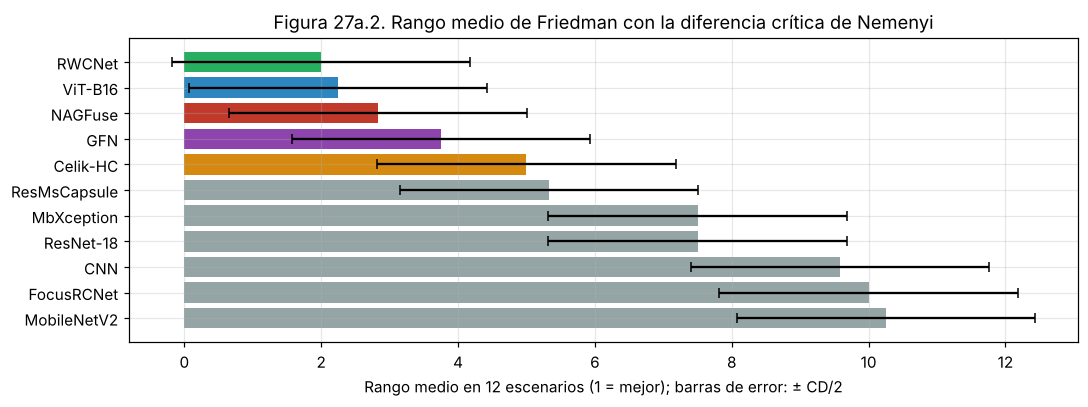

In [7]:
# Figura 27a.2: comparación global (Friedman + Iman–Davenport + Nemenyi) sobre 12 escenarios
F = pd.read_csv(RES / "friedman_nemenyi.csv").sort_values("rango_medio")
print(f"χ²_F = {F.chi2.iloc[0]:.2f}, F_ID = {F.F_ID.iloc[0]:.2f}, p = {F.p.iloc[0]:.1e}, CD = {F.CD.iloc[0]:.2f}")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(F.modelo, F.rango_medio, xerr=F.CD.iloc[0] / 2, color=[COLOR.get(m, "#95a5a6") for m in F.modelo],
        error_kw=dict(ecolor="black", capsize=3))
ax.invert_yaxis(); ax.set_xlabel("Rango medio en 12 escenarios (1 = mejor); barras de error: ± CD/2")
ax.set_title("Figura 27a.2. Rango medio de Friedman con la diferencia crítica de Nemenyi")
plt.tight_layout()

**Interpretación.** Dos modelos difieren significativamente según Nemenyi cuando sus rangos medios se separan más que
la diferencia crítica CD (equivalentemente, cuando sus barras de ± CD/2 no se solapan). RWCNet (2.00), ViT-B16 (2.25),
NAGFuse (2.83) y GFN (3.75) forman el grupo de cabeza y no se distinguen entre sí con CD = 4.36: la comparación global
respalda un desempeño de primer nivel, no una superioridad.